# AI-Powered Retail Banking Customer Intelligence

## Business Problem
A retail bank wants to understand customer behavior, identify meaningful customer segments, and discover opportunities for targeted marketing and product adoption.

## Project Objectives
1. Explore and clean a real-world banking dataset.
2. Identify meaningful customer characteristics and patterns.
3. Compare clustering approaches including K-Means, hierarchical clustering, and DBSCAN.
4. Evaluate PCA for dimensionality reduction.
5. Develop actionable business recommendations.
6. Build a Power BI dashboard and an AI-assisted insights experience.

## Current Stage
Phase 1: Dataset selection and exploratory data analysis.

**Note:** Findings and recommendations will be based on the capabilities and limitations of the selected dataset.

In [2]:

import pandas as pd
import numpy as np

from google.colab import files

uploaded = files.upload()


Saving CC GENERAL.csv to CC GENERAL.csv


In [7]:

df = pd.read_csv("CC GENERAL.csv")

print("Dataset shape:", df.shape)
display(df.head())





Dataset shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [9]:
df.isna().sum()

,0
CUST_ID,0
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,0
PURCHASES_INSTALLMENTS_FREQUENCY,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe(include="all")

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
unique,8950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,C10001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,NaN,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,NaN,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,NaN,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,NaN,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000


In [12]:

df["MINIMUM_PAYMENTS"].describe()


,MINIMUM_PAYMENTS
count,8637.000000
mean,864.206542
std,2372.446607
min,0.019163
25%,169.123707
50%,312.343947
75%,825.485459
max,76406.207520


In [13]:
df['CUST_ID']

,CUST_ID
0,C10001
1,C10002
2,C10003
3,C10004
4,C10005
...,...
8945,C19186
8946,C19187
8947,C19188
8948,C19189


In [14]:

df.loc[
    df["MINIMUM_PAYMENTS"].isna(),
    ["BALANCE", "PURCHASES", "CREDIT_LIMIT", "PAYMENTS"]
].describe()



,BALANCE,PURCHASES,CREDIT_LIMIT,PAYMENTS
count,313.000000,313.000000,313.000000,313.000000
mean,555.441321,393.087284,3731.789137,322.286168
std,1292.687887,757.905701,2924.606153,1996.658905
min,0.000000,0.000000,500.000000,0.000000
25%,0.187069,1.400000,1500.000000,0.000000
50%,16.848358,130.400000,3000.000000,0.000000
75%,286.686616,399.950000,5000.000000,0.000000
max,9164.724752,7597.090000,19500.000000,29272.486070


In [15]:

# Compare customer behavior to check whether missing minimum payments follow a pattern.
# Use medians to reduce the influence of unusually large financial values.

missing_payment_comparison = df.groupby(
    df["MINIMUM_PAYMENTS"].isna()
)[["BALANCE", "PURCHASES", "PAYMENTS", "CREDIT_LIMIT"]].median()

display(missing_payment_comparison)


,BALANCE,PURCHASES,PAYMENTS,CREDIT_LIMIT
MINIMUM_PAYMENTS,,,,
False,916.749476,375.24,896.300688,3000.0
True,16.848358,130.40,0.000000,3000.0


In [16]:

# Preserve the original dataset before making any changes.
df_original = df.copy()

# Flag missing minimum payments before replacing them.
df["MIN_PAYMENT_MISSING"] = df["MINIMUM_PAYMENTS"].isna().astype(int)

# Fill missing values with their respective column medians.
df["MINIMUM_PAYMENTS"] = df["MINIMUM_PAYMENTS"].fillna(df["MINIMUM_PAYMENTS"].median())
df["CREDIT_LIMIT"] = df["CREDIT_LIMIT"].fillna(df["CREDIT_LIMIT"].median())

print("Remaining missing values:", df.isna().sum().sum())
print("Original missing values:", df_original.isna().sum().sum())
print("Flagged customers:", df["MIN_PAYMENT_MISSING"].sum())


Remaining missing values: 0
Original missing values: 314
Flagged customers: 313


## Exploratory Data Analysis (EDA)

### Distribution of Key Financial Features

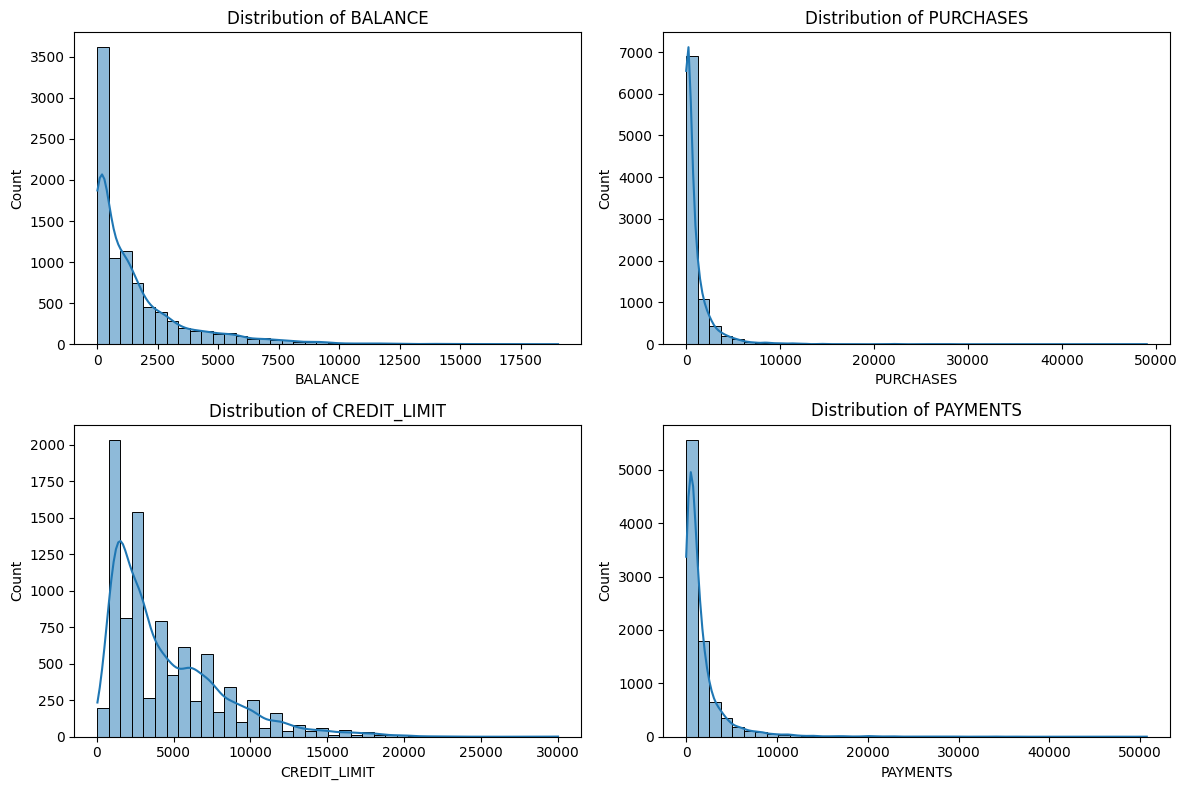

In [17]:

import matplotlib.pyplot as plt
import seaborn as sns

# Examine financial distributions to identify skewness and extreme customer values.
features = ["BALANCE", "PURCHASES", "CREDIT_LIMIT", "PAYMENTS"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, features):
    sns.histplot(df[col], bins=40, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()


### Initial Distribution Findings

Balances, purchases, credit limits, and payments exhibit right-skewed distributions.

Purchases and payments have particularly long tails, indicating a small group of customers with unusually high values.

These observations suggest that transformations and robust scaling should be evaluated before distance-based clustering. Extreme values will be investigated rather than automatically removed.

In [18]:

# Measure distribution asymmetry to identify features that may need transformation.
features = ["BALANCE", "PURCHASES", "CREDIT_LIMIT", "PAYMENTS"]

df[features].skew().sort_values(ascending=False)


,0
PURCHASES,8.144269
PAYMENTS,5.907620
BALANCE,2.393386
CREDIT_LIMIT,1.522636


### Outlier Analysis — Boxplots

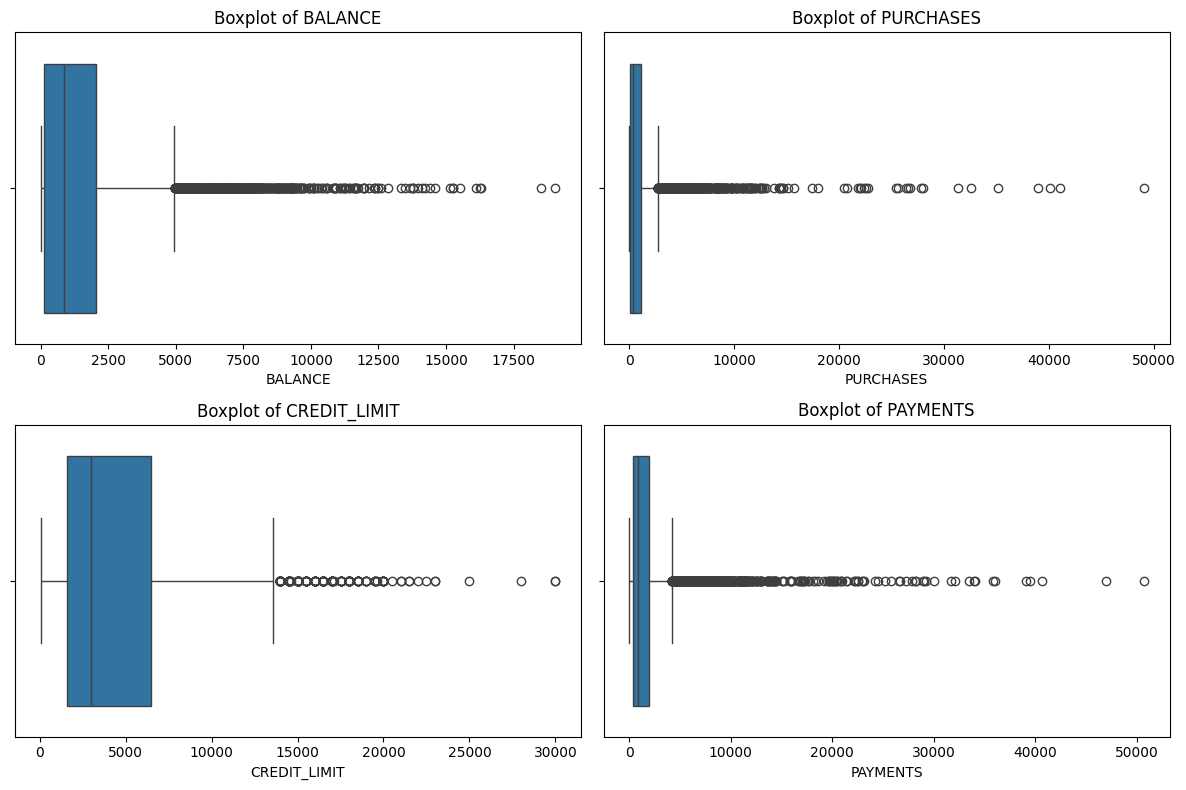

In [19]:

# Visualize potential outliers and the spread of key financial features.
features = ["BALANCE", "PURCHASES", "CREDIT_LIMIT", "PAYMENTS"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, features):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()


### EDA Findings — Distributions, Outliers and Skewness

**Distribution analysis:** Most customers have relatively low balances, purchases and payments, while a small number have exceptionally high values. This creates **right-skewed distributions**, where most observations are concentrated on the left and the distribution extends far to the right.

**Boxplot analysis:** All four financial features contain upper-end outliers. These may represent genuine high-value banking customers, so we will not automatically remove them.

**Skewness results:**
- Purchases: **8.14** — Extremely right-skewed.
- Payments: **5.91** — Extremely right-skewed.
- Balance: **2.39** — Strongly right-skewed.
- Credit Limit: **1.52** — Moderately right-skewed.

**Business interpretation:** Customer financial activity varies considerably. A relatively small group of customers has much higher purchase amounts, payments or balances than the majority. These differences may help identify distinct customer segments.

**Next decision:** Test log transformation to reduce the influence of extreme values before scaling and clustering, while retaining the original financial values for business reporting.

### Preprocessing Strategy

1. **Examine distributions and outliers:** Identify skewness and extreme values without automatically removing valid high-value customers.
2. **Log transformation:** Test `log1p()` on strongly right-skewed, non-negative features to reduce the influence of extreme values.
3. **Feature scaling:** Apply StandardScaler or RobustScaler to make features comparable for distance-based algorithms.
4. **Model evaluation:** Compare preprocessing choices using clustering metrics, stability, and business interpretability.

**Note:** Preserve original financial values for reporting. Log transformation changes distribution shape; scaling adjusts feature magnitude. Neither automatically removes outliers.

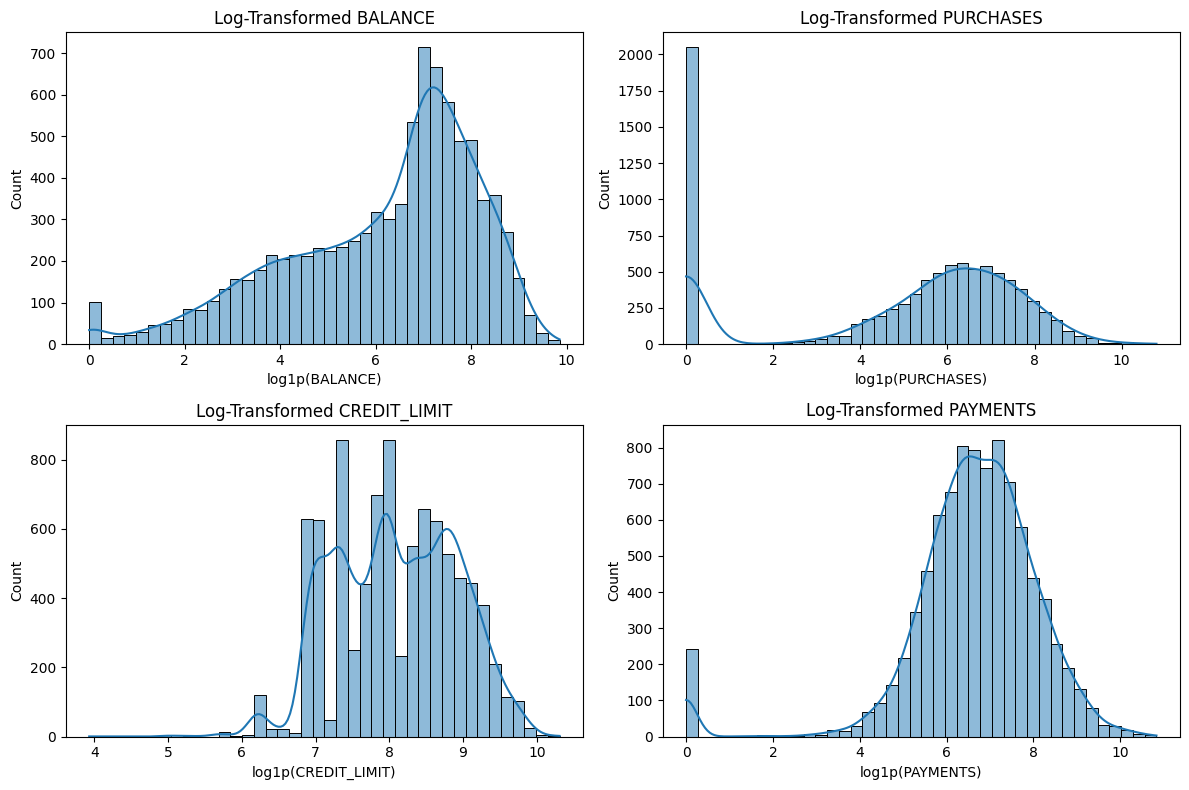

,Before,After
BALANCE,2.39,-0.86
PURCHASES,8.14,-0.76
CREDIT_LIMIT,1.52,-0.10
PAYMENTS,5.91,-1.78


In [20]:

# Test log transformation to reduce the influence of extreme financial values.
# Compare transformed distributions and skewness without modifying df.

features = ["BALANCE", "PURCHASES", "CREDIT_LIMIT", "PAYMENTS"]

df_log = np.log1p(df[features])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, features):
    sns.histplot(df_log[col], bins=40, kde=True, ax=ax)
    ax.set_title(f"Log-Transformed {col}")
    ax.set_xlabel(f"log1p({col})")

plt.tight_layout()
plt.show()

# Compare skewness before and after transformation.
skew_comparison = pd.DataFrame({
    "Before": df[features].skew(),
    "After": df_log.skew()
})

display(skew_comparison.round(2))


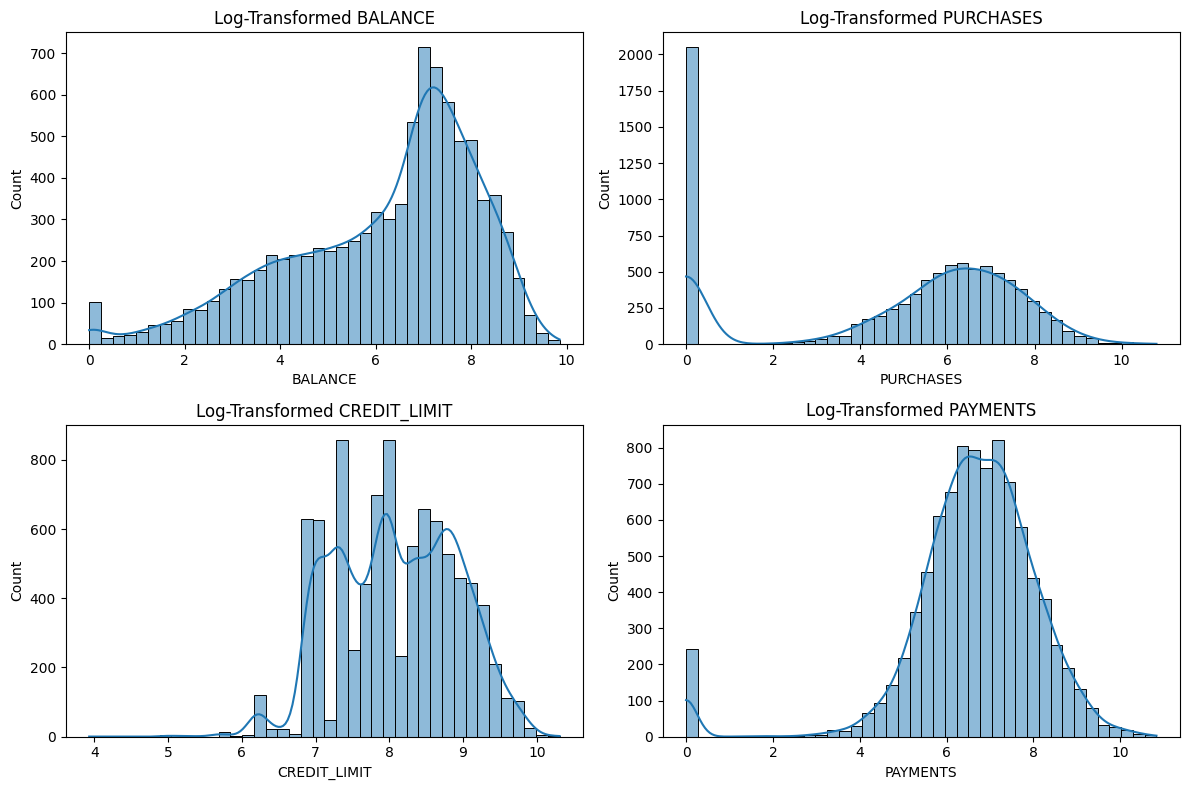

,Before,After
BALANCE,2.39,-0.86
PURCHASES,8.14,-0.76
CREDIT_LIMIT,1.52,-0.10
PAYMENTS,5.91,-1.78


In [21]:

# Test whether log transformation reduces skewness in financial features.
# Keep the original df unchanged for comparison and business reporting.

features = ["BALANCE", "PURCHASES", "CREDIT_LIMIT", "PAYMENTS"]

df_log = np.log1p(df[features])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, features):
    sns.histplot(df_log[col], bins=40, kde=True, ax=ax)
    ax.set_title(f"Log-Transformed {col}")

plt.tight_layout()
plt.show()

skew_comparison = pd.DataFrame({
    "Before": df[features].skew(),
    "After": df_log.skew()
})

display(skew_comparison.round(2))


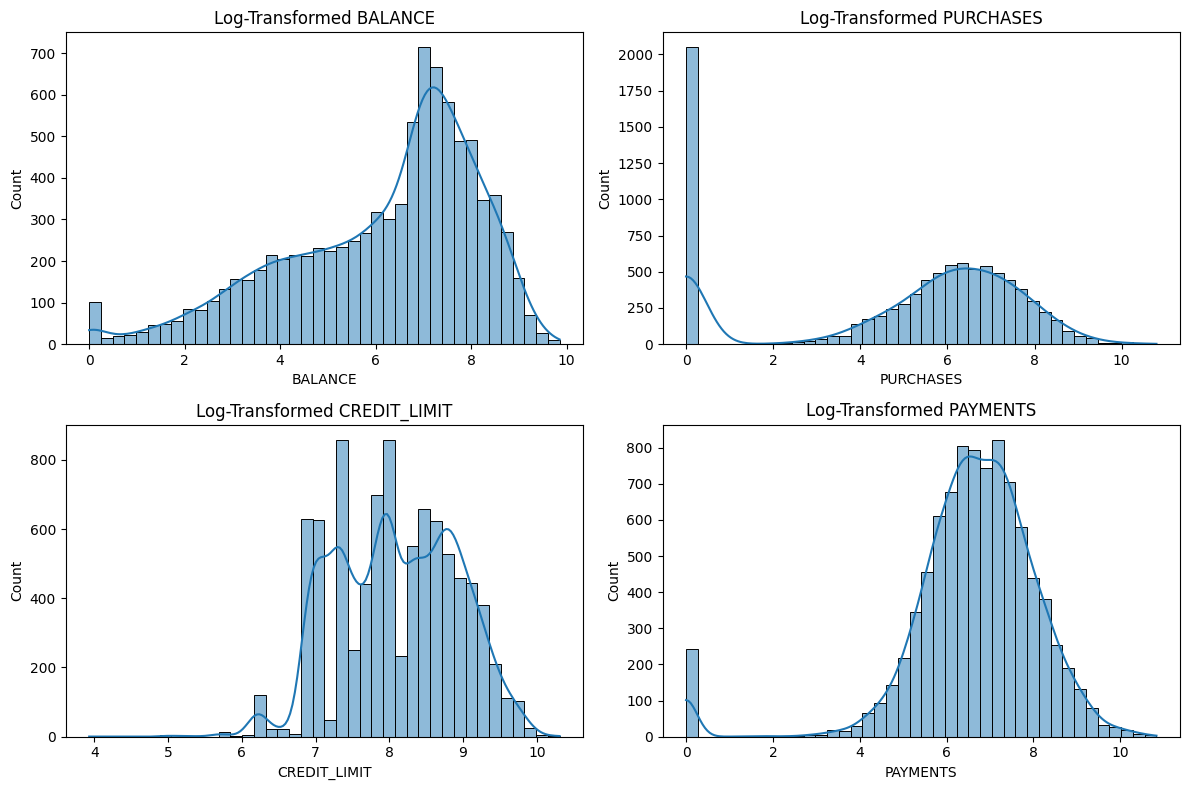

,Before,After
BALANCE,2.39,-0.86
PURCHASES,8.14,-0.76
CREDIT_LIMIT,1.52,-0.10
PAYMENTS,5.91,-1.78


In [22]:

# Test whether log transformation reduces skewness in financial features.
# Keep the original df unchanged for comparison and business reporting.

features = ["BALANCE", "PURCHASES", "CREDIT_LIMIT", "PAYMENTS"]

df_log = np.log1p(df[features])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, features):
    sns.histplot(df_log[col], bins=40, kde=True, ax=ax)
    ax.set_title(f"Log-Transformed {col}")

plt.tight_layout()
plt.show()

skew_comparison = pd.DataFrame({
    "Before": df[features].skew(),
    "After": df_log.skew()
})

display(skew_comparison.round(2))


### Log Transformation — Findings

Log transformation substantially reduced the original right-skewness of all four financial features.

- **Balance:** Skewness changed from 2.39 to -0.88.
- **Purchases:** Changed from 8.14 to -0.76. A large spike at zero remains, indicating many customers with no recorded purchases.
- **Credit Limit:** Changed from 1.52 to -0.10, producing a nearly symmetric distribution.
- **Payments:** Changed from 5.91 to -1.78, indicating that the transformation introduced substantial left-skewness.

**Business interpretation:** Customer financial activity varies widely, including customers with no recorded purchases or payments and customers with much higher activity. Log transformation reduces the numerical influence of extreme amounts while preserving these observations.

**Decision:** Log transformation is promising, but we will not automatically apply it to every feature. We will retain the original data and evaluate preprocessing choices before clustering.

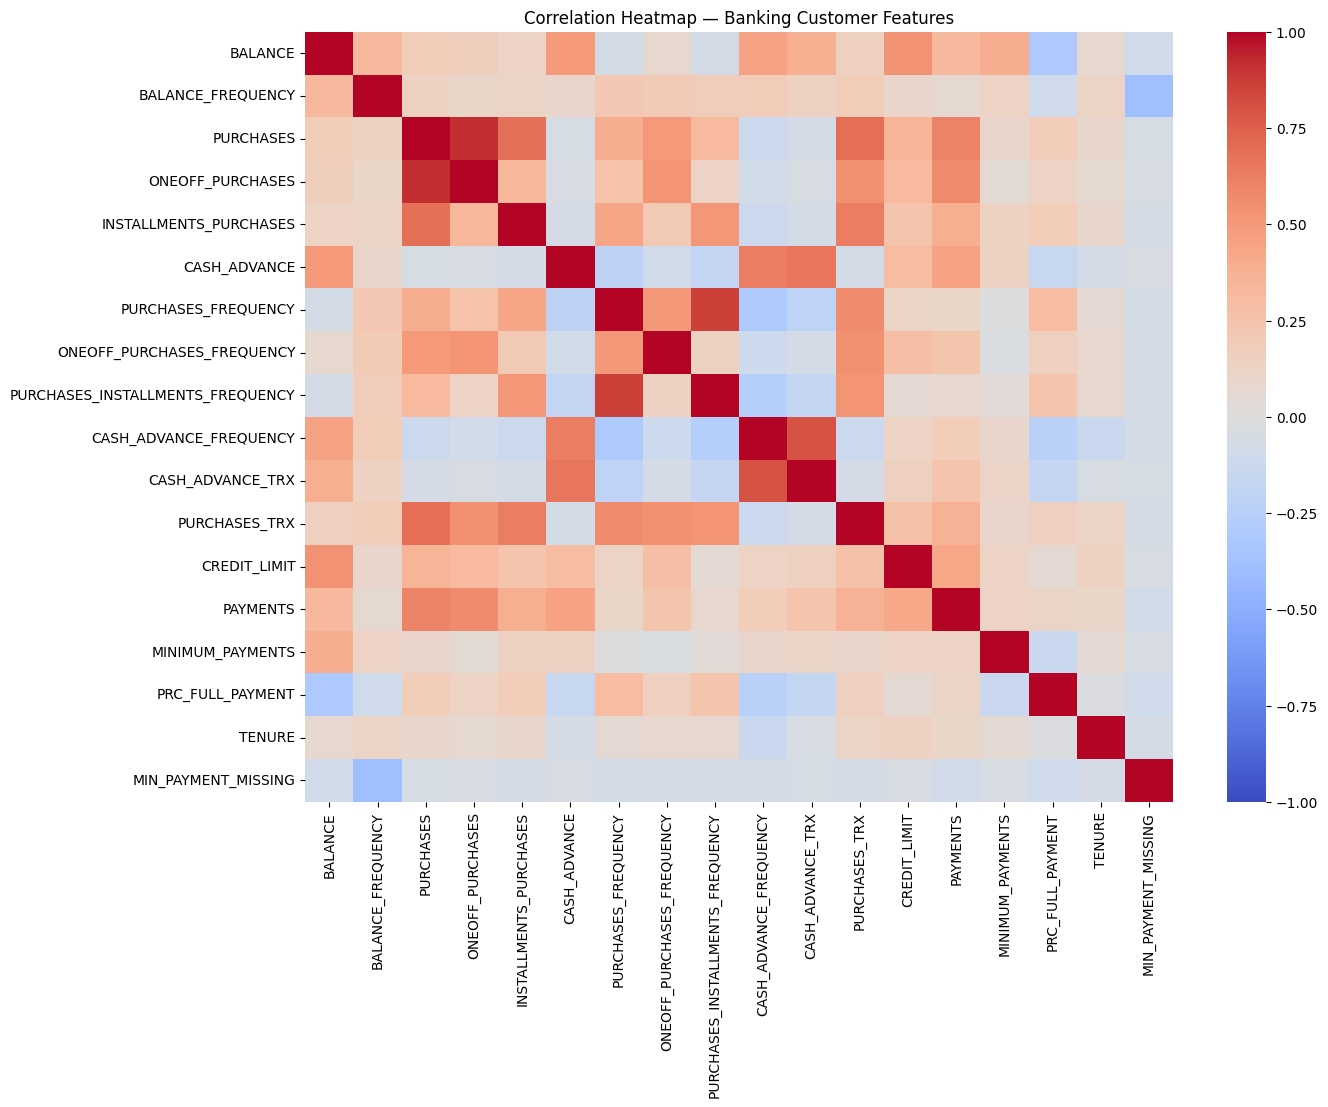

In [23]:

# Check relationships between financial features before selecting clustering inputs.
# Strong correlations may indicate overlapping customer information.

corr = df.drop(columns=["CUST_ID"]).corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Heatmap — Banking Customer Features")
plt.show()


### Correlation Analysis — Findings

The correlation heatmap shows several relationships between customer financial behaviors.

- Total purchases are strongly associated with one-off purchases and purchase transaction counts.
- Cash advance frequency and cash advance transaction counts are strongly related.
- Purchase frequency and installment purchase frequency show a strong positive relationship.
- Balance and full-payment percentage show a negative relationship.

**Business interpretation:** Customers demonstrate different spending, borrowing and repayment patterns. These relationships may help identify meaningful customer segments.

**Modeling consideration:** Some features contain overlapping information. We will review these relationships when selecting features for clustering rather than automatically removing correlated variables.

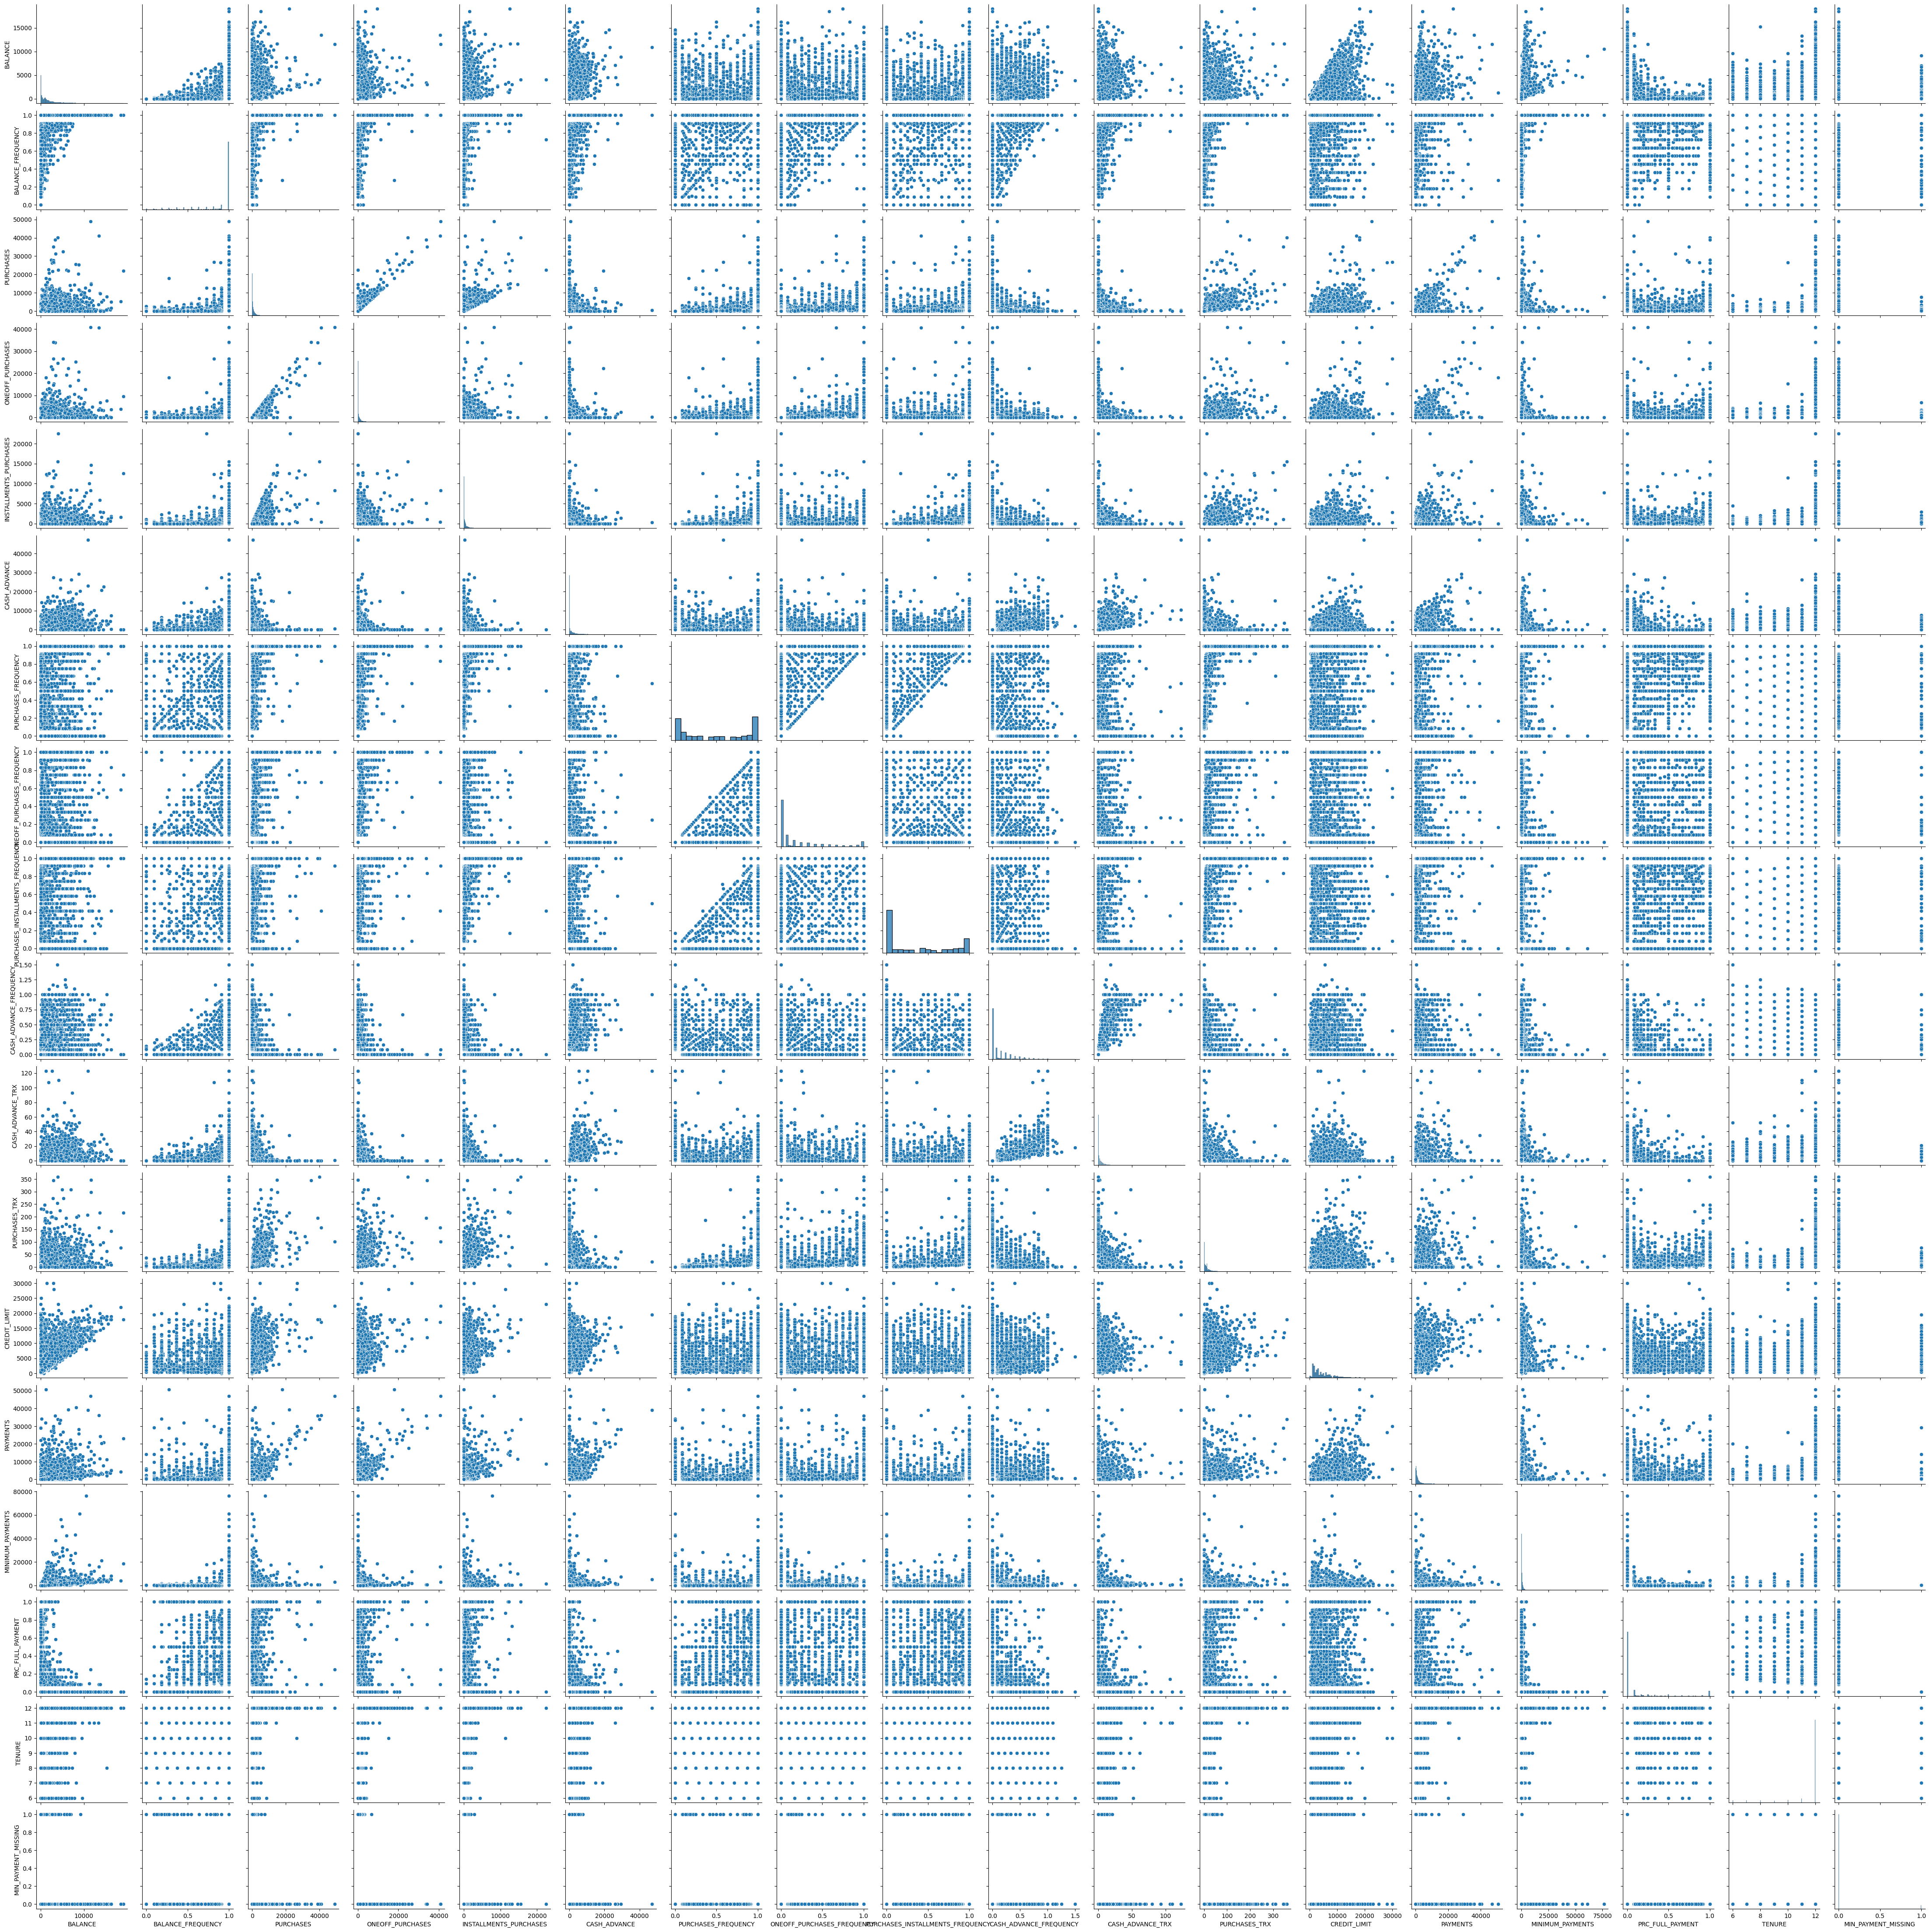

In [24]:
# sns.pairplot(df)

In [25]:

# List the strongest relationships without repeating pairs or self-correlations.
# This helps identify features that may contain overlapping information.

corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

strong_corr = corr_pairs.stack().sort_values(ascending=False)

display(strong_corr.head(10).round(2))


PURCHASES               ONEOFF_PURCHASES                    0.92
PURCHASES_FREQUENCY     PURCHASES_INSTALLMENTS_FREQUENCY    0.86
CASH_ADVANCE_FREQUENCY  CASH_ADVANCE_TRX                    0.80
PURCHASES               PURCHASES_TRX                       0.69
                        INSTALLMENTS_PURCHASES              0.68
CASH_ADVANCE            CASH_ADVANCE_TRX                    0.66
                        CASH_ADVANCE_FREQUENCY              0.63
INSTALLMENTS_PURCHASES  PURCHASES_TRX                       0.63
PURCHASES               PAYMENTS                            0.60
PURCHASES_FREQUENCY     PURCHASES_TRX                       0.57
dtype: float64

### Strong Correlations — Key Findings

The strongest positive correlations are:

- Purchases and One-off Purchases: **0.92**
- Purchase Frequency and Installment Frequency: **0.86**
- Cash Advance Frequency and Transactions: **0.80**
- Purchases and Purchase Transactions: **0.69**
- Purchases and Payments: **0.60**

**Business interpretation:** Customer spending amounts, purchase activity and cash-advance usage show related behavioral patterns.

**Modeling decision:** Some features contain overlapping information. We will start with a smaller set of meaningful features representing different customer behaviors, rather than automatically including every available column.

### Correlated Features and PCA — Modeling Decision

The correlation analysis identified strongly related features, particularly purchases and one-off purchases (0.92).

Strong correlations indicate overlapping information. Although multicollinearity is not a strict problem for K-Means, correlated features can give certain customer behaviors more influence during distance calculations.

**Our approach:**
1. Start with a smaller set of business-relevant features to build an interpretable K-Means model.
2. Apply PCA later as an optional dimensionality-reduction experiment.
3. Compare the results and retain the approach that produces useful, understandable customer segments.

PCA is not mandatory, and we do not need to eliminate every correlation.

In [26]:

# Select features representing spending, borrowing, and repayment behavior.
# Create a separate dataset without changing the original df.

selected_features = [
    "BALANCE",
    "PURCHASES",
    "PURCHASES_FREQUENCY",
    "CASH_ADVANCE",
    "CASH_ADVANCE_FREQUENCY",
    "CREDIT_LIMIT",
    "PAYMENTS",
    "PRC_FULL_PAYMENT"
]

X = df[selected_features].copy()

print("Clustering dataset shape:", X.shape)
display(X.head())


Clustering dataset shape: (8950, 8)


,BALANCE,PURCHASES,PURCHASES_FREQUENCY,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT
0,40.900749,95.40,0.166667,0.000000,0.000000,1000.0,201.802084,0.000000
1,3202.467416,0.00,0.000000,6442.945483,0.250000,7000.0,4103.032597,0.222222
2,2495.148862,773.17,1.000000,0.000000,0.000000,7500.0,622.066742,0.000000
3,1666.670542,1499.00,0.083333,205.788017,0.083333,7500.0,0.000000,0.000000
4,817.714335,16.00,0.083333,0.000000,0.000000,1200.0,678.334763,0.000000


In [27]:

# Reduce the influence of extremely large financial amounts.
# Keep X unchanged so we can compare preprocessing approaches later.

X_transformed = X.copy()

log_features = [
    "BALANCE",
    "PURCHASES",
    "CASH_ADVANCE",
    "CREDIT_LIMIT",
    "PAYMENTS"
]

X_transformed[log_features] = np.log1p(X_transformed[log_features])

display(X_transformed.head())


,BALANCE,PURCHASES,PURCHASES_FREQUENCY,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT
0,3.735304,4.568506,0.166667,0.000000,0.000000,6.908755,5.312231,0.000000
1,8.071989,0.000000,0.000000,8.770896,0.250000,8.853808,8.319725,0.222222
2,7.822504,6.651791,1.000000,0.000000,0.000000,8.922792,6.434654,0.000000
3,7.419183,7.313220,0.083333,5.331694,0.083333,8.922792,0.000000,0.000000
4,6.707735,2.833213,0.083333,0.000000,0.000000,7.090910,6.521114,0.000000


### Feature Scaling — StandardScaler

After log transformation, the selected features still have different numerical ranges.

StandardScaler standardizes each feature to approximately zero mean and unit standard deviation, allowing the features to contribute on comparable scales during distance-based clustering.

**Business purpose:** Customer segments should reflect a combination of spending, borrowing and repayment behavior rather than being dominated by features with larger numerical values.

In [28]:

from sklearn.preprocessing import StandardScaler

# Standardize the eight features so they have comparable scales.
# Keep the scaled data separate for clustering.

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_transformed),
    columns=X_transformed.columns,
    index=X_transformed.index
)

display(X_scaled.head())

print("Feature means:")
display(X_scaled.mean().round(2))

print("Feature standard deviations:")
display(X_scaled.std(ddof=0).round(2))


,BALANCE,PURCHASES,PURCHASES_FREQUENCY,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT
0,-1.205218,-0.113532,-0.806490,-0.930733,-0.675349,-1.447163,-0.824484,-0.525551
1,0.948918,-1.679855,-1.221758,1.528788,0.573963,0.926060,1.065033,0.234227
2,0.824993,0.600727,1.269843,-0.930733,-0.675349,1.010229,-0.119300,-0.525551
3,0.624653,0.827499,-1.014125,0.564372,-0.258913,1.010229,-4.161996,-0.525551
4,0.271260,-0.708481,-1.014125,-0.930733,-0.675349,-1.224909,-0.064979,-0.525551


Feature means:


,0
BALANCE,0.0
PURCHASES,0.0
PURCHASES_FREQUENCY,-0.0
CASH_ADVANCE,0.0
CASH_ADVANCE_FREQUENCY,0.0
CREDIT_LIMIT,-0.0
PAYMENTS,0.0
PRC_FULL_PAYMENT,0.0


Feature standard deviations:


,0
BALANCE,1.0
PURCHASES,1.0
PURCHASES_FREQUENCY,1.0
CASH_ADVANCE,1.0
CASH_ADVANCE_FREQUENCY,1.0
CREDIT_LIMIT,1.0
PAYMENTS,1.0
PRC_FULL_PAYMENT,1.0


### K-Means — Choosing the Number of Clusters

The Elbow Method helps identify a suitable number of customer segments by comparing K-Means inertia across different cluster counts.

Inertia measures how closely customers are grouped around their cluster centers. Lower inertia indicates more compact clusters, but it naturally decreases as the number of clusters increases.

**Business purpose:** Find a manageable number of customer segments that capture meaningful differences in spending, borrowing and repayment behavior.

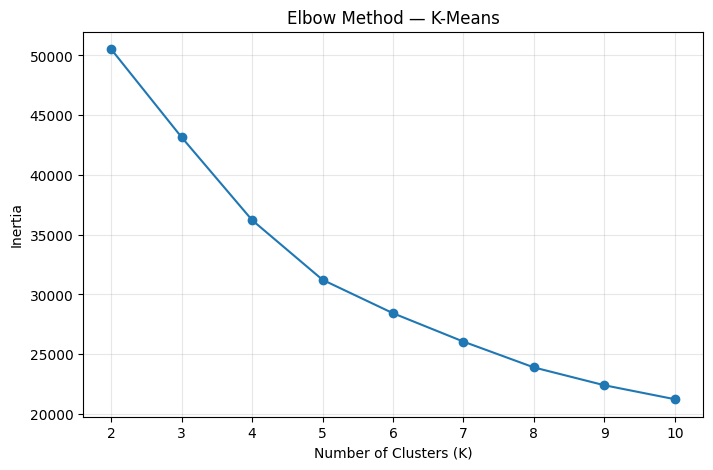

In [32]:
"""
from sklearn.cluster import KMeans

# Test different numbers of clusters to identify a suitable K.
# Plot inertia to look for the point where improvements begin to slow.

k_values = range(2, 11)
inertia = []

for k in k_values:
    model = KMeans(
    n_clusters=k,
    init="k-means++",  # Default centroid initialization in scikit-learn . We dont have to mention  it explicitly
    random_state=42,
    n_init=10
)

    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method — K-Means")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.show()

"""

# Plot inertia to look for the point where improvements begin to slow.
# Store fitted models so they can be reused for silhouette analysis.


from sklearn.cluster import KMeans

# Fit K-Means for different cluster counts and save each model.
# Reuse the fitted models for silhouette analysis without retraining.

k_values = range(2, 11)
models = {}
inertia = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",  # Default centroid initialization
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    models[k] = model
    inertia.append(model.inertia_)

# Plot inertia to identify a possible elbow.
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method — K-Means")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.show()



### Elbow Method — Findings

Inertia decreases as the number of clusters increases. The curve begins to flatten around K = 5, although there is no clearly defined elbow.

**Decision:** Consider K = 4, 5 and 6 as possible cluster counts. Use the Silhouette Score to help select a suitable K.

**Business interpretation:** We want enough customer segments to capture meaningful differences in behavior without creating too many small or difficult-to-interpret groups.

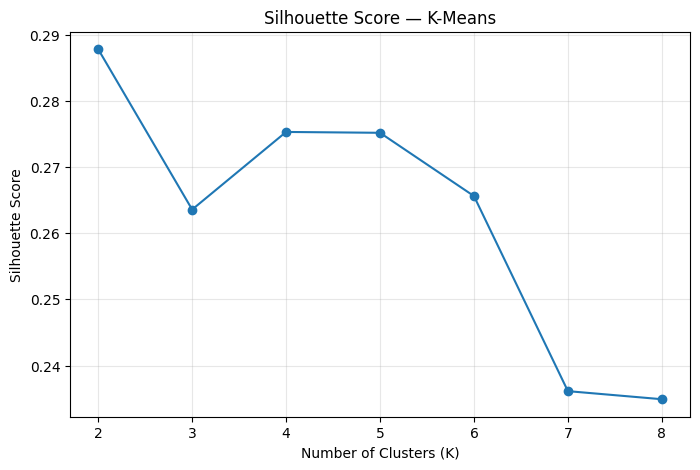

,K,Silhouette Score
0,2,0.288
1,3,0.264
2,4,0.275
3,5,0.275
4,6,0.266
5,7,0.236
6,8,0.235


In [35]:
"""
from sklearn.metrics import silhouette_score

# Compare cluster separation across different K values.
# Use a sample to reduce computation time.

silhouette_scores = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, init="k-means++",
                   random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled, labels, sample_size=2000, random_state=42
    )
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 9), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score — K-Means")
plt.xticks(range(2, 9))
plt.grid(alpha=0.3)
plt.show()
"""


from sklearn.metrics import silhouette_score

# Evaluate how well customers are grouped and separated.
# Reuse fitted K-Means models from Step 16 without retraining.

k_values = range(2, 9)
silhouette_scores = []

for k in k_values:
    score = silhouette_score(
        X_scaled,
        models[k].labels_,
        sample_size=2000,
        random_state=42
    )
    silhouette_scores.append(score)

# Plot silhouette scores for different cluster counts.
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score — K-Means")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.show()

# Display the scores for comparison.
results = pd.DataFrame({
    "K": list(k_values),
    "Silhouette Score": silhouette_scores
})

display(results.round(3))


### Silhouette Score — Findings

The highest Silhouette Score occurs at **K = 2 (0.288)**. However, K = 4 and K = 5 both achieve approximately **0.275**, indicating similar cluster separation.

The Elbow Method suggests a possible elbow around K = 5.

**Decision:** Provisionally select **K = 5** for our first K-Means model, balancing cluster separation with the business objective of identifying meaningful customer segments.

We will examine cluster sizes and customer behavior before confirming this choice. K = 2 and K = 4 remain alternatives for comparison.

In [36]:

# Select the previously fitted K-Means model with five clusters.
# Reuse the existing model instead of fitting it again.

optimal_k = 5
kmeans_model = models[optimal_k]

print("Selected number of clusters:", kmeans_model.n_clusters)
print("Inertia:", round(kmeans_model.inertia_, 2))
print("Number of customers:", len(kmeans_model.labels_))


Selected number of clusters: 5
Inertia: 31223.88
Number of customers: 8950


In [37]:

# Assign each customer to a cluster using our fitted K-Means model.
# Preserve the original financial values for business analysis.

df_clustered = df.copy()

df_clustered["Cluster"] = kmeans_model.labels_

display(df_clustered[["CUST_ID", "BALANCE", "PURCHASES", "PAYMENTS", "Cluster"]].head())

print("Customers in each cluster:")
display(df_clustered["Cluster"].value_counts().sort_index())


,CUST_ID,BALANCE,PURCHASES,PAYMENTS,Cluster
0,C10001,40.900749,95.40,201.802084,3
1,C10002,3202.467416,0.00,4103.032597,1
2,C10003,2495.148862,773.17,622.066742,2
3,C10004,1666.670542,1499.00,0.000000,3
4,C10005,817.714335,16.00,678.334763,2


Customers in each cluster:


,count
Cluster,
0,1641
1,2195
2,2491
3,1338
4,1285


### Analyzing Customer Clusters

Now that we have divided customers into five clusters, let's compare their average balances, purchases, cash advances, payments, and credit limits.

This will help us understand the spending and borrowing patterns of customers in each cluster and identify how the groups differ.

In [45]:
df_clustered.groupby("Cluster")[["BALANCE", "PURCHASES", "PAYMENTS","CASH_ADVANCE","CREDIT_LIMIT"]].mean().round(2)

,BALANCE,PURCHASES,PAYMENTS,CASH_ADVANCE,CREDIT_LIMIT
Cluster,,,,,
0,3205.60,1391.10,2901.84,2600.30,5959.90
1,2173.94,12.59,1631.06,1951.22,3916.84
2,1428.02,1575.59,1703.95,13.46,4578.28
3,138.90,263.85,279.10,99.51,2872.72
4,176.51,1860.24,1985.67,34.40,5134.59


### What Did We Learn?

Our analysis shows that customers have different spending and borrowing habits.

- **Cluster 0:** These customers have high outstanding balances and take the largest cash advances. They may rely more heavily on credit.
- **Cluster 1:** These customers make very few purchases but take large cash advances. They appear to use their credit cards mainly for accessing cash.
- **Cluster 2:** These customers spend regularly on purchases but rarely take cash advances.
- **Cluster 3:** These customers have low balances and make relatively small purchases. They appear to be less active credit card users.
- **Cluster 4:** These customers spend the most on purchases but maintain low outstanding balances. They may be paying off their balances more regularly.

**What does this mean for the bank?**

Not all customers use their credit cards in the same way. Some mainly use them for purchases, others rely more on cash advances, and some use their cards very little.

Understanding these differences can help the bank offer more relevant services and communicate with customers based on their needs.

### Comparing Customer Segments

We tested different numbers of customer groups. Although two clusters gave the highest silhouette score, four and five clusters also produced similar results.

Let's compare how customers are grouped under each option.

The goal is to find a number of segments that is easy for the bank to understand and useful for identifying different spending, borrowing, and repayment habits.

In [48]:

# Compare customer profiles for K = 2, 4, and 5 using existing fitted models.
# Use original financial values to make the results easy to interpret.

cluster_summaries = []

for k in [2, 4, 5]:
    temp_df = df.copy()
    temp_df["Cluster"] = models[k].labels_

    summary = temp_df.groupby("Cluster").agg(
        Customers=("CUST_ID", "count"),
        Avg_Balance=("BALANCE", "mean"),
        Avg_Purchases=("PURCHASES", "mean"),
        Avg_Cash_Advance=("CASH_ADVANCE", "mean"),
        Avg_Full_Payment=("PRC_FULL_PAYMENT", "mean")
    ).reset_index()

    summary.insert(0, "K", k)
    cluster_summaries.append(summary)

comparison_df = pd.concat(cluster_summaries, ignore_index=True)

display(comparison_df.round(2))


,K,Cluster,Customers,Avg_Balance,Avg_Purchases,Avg_Cash_Advance,Avg_Full_Payment
0,2,0,5120,820.91,1394.21,41.57,0.24
1,2,1,3830,2558.48,480.50,2231.87,0.04
2,4,0,1698,3309.22,1639.37,2503.89,0.04
3,4,1,2323,2066.47,14.53,1892.10,0.03
4,4,2,3554,938.13,1023.97,19.72,0.05
5,4,3,1375,180.72,1834.25,31.90,0.77
6,5,0,1641,3205.60,1391.10,2600.30,0.04
7,5,1,2195,2173.94,12.59,1951.22,0.03
8,5,2,2491,1428.02,1575.59,13.46,0.04
9,5,3,1338,138.90,263.85,99.51,0.09


### What Did We Learn?

We compared customer groups using two, four, and five clusters.

With **two clusters**, customers are mainly separated into purchase-focused and cash-advance-focused groups. This is easy to understand but does not capture all differences in customer behavior.

With **four clusters**, we can identify more specific groups, including customers who frequently pay their balances in full.

With **five clusters**, we can also distinguish customers with low financial activity from customers who make substantial purchases and frequently pay in full.

**Our decision:** Five clusters appear to provide useful additional information without making the groups too difficult to understand. We will continue with five clusters for now and examine customer activity and repayment patterns before finalizing the segments.

### Understanding Customer Activity and Repayment

We have identified five customer groups based on their spending and borrowing patterns.

Now let's compare how frequently customers make purchases, take cash advances, and pay their balances in full.

This will help us understand each group better before assigning meaningful names.

In [54]:
df_clustered.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 20 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [57]:
df_clustered.groupby("Cluster").agg(
    Avg_Purchases_Freq=("PURCHASES_FREQUENCY", "mean"),
    Avg_Cash_Advance_Freq=("CASH_ADVANCE_FREQUENCY", "mean"),
    Avg_Full_Payment_Prf=("PRC_FULL_PAYMENT", "mean"),
    Customer_Count=("CUST_ID", "count")
).round(2)

,Avg_Purchases_Freq,Avg_Cash_Advance_Freq,Avg_Full_Payment_Prf,Customer_Count
Cluster,,,,
0,0.64,0.33,0.04,1641
1,0.01,0.28,0.03,2195
2,0.69,0.01,0.04,2491
3,0.42,0.02,0.09,1338
4,0.80,0.01,0.79,1285


### What Did We Learn?

Our analysis shows that the five customer groups have different spending, borrowing, and repayment habits.

- **High Credit Users:** Maintain high balances and use cash advances frequently.
- **Cash-Advance Users:** Make very few purchases but use their cards to access cash.
- **Regular Purchasers:** Make purchases frequently but rarely pay their entire balance in full.
- **Low-Activity Customers:** Have relatively low balances and purchase amounts.
- **Frequent Full-Payment Customers:** Make purchases frequently and usually pay their balances in full.

**What does this mean for the bank?**

These groups could help the bank better understand how customers use their credit cards. For example, it could explore ways to encourage low-activity customers to use their cards more, while offering suitable services to customers with different borrowing and repayment habits.

The five-cluster model appears useful because it identifies differences beyond simply active and inactive customers.

### Comparing Customer Spending Across Clusters

Let's create a bar chart showing the average purchase amount for each customer group.

This will help us see which groups spend more and which spend less, making the differences easier to understand.

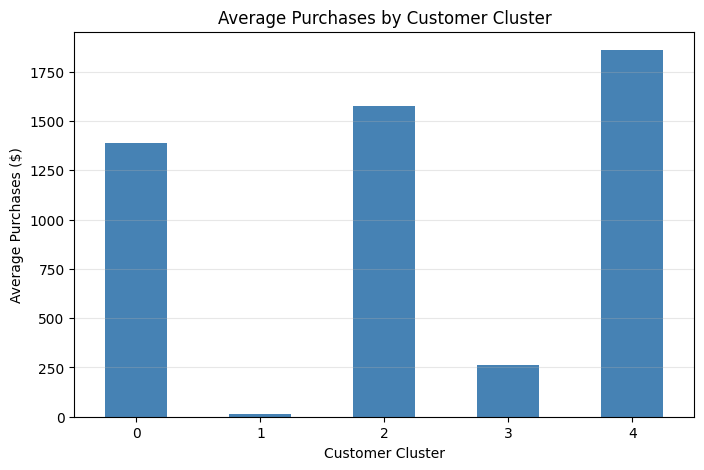

In [58]:

# Calculate average purchases for each customer cluster.
# Visualize spending differences using original purchase amounts.

avg_purchases = df_clustered.groupby("Cluster")["PURCHASES"].mean()

plt.figure(figsize=(8, 5))
avg_purchases.plot(kind="bar", color="steelblue")

plt.title("Average Purchases by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Purchases ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


### What Did We Learn?

The chart shows clear differences in how much customers spend across the five groups.

- **Cluster 4:** Highest average purchases ($1,860). These customers also tend to pay their balances in full frequently.

- **Cluster 2:** High average purchases ($1,576), but customers pay their full balances much less frequently.

- **Cluster 0:** Moderate-to-high purchases ($1,391), along with substantial cash-advance usage.

- **Cluster 3:** Relatively low purchases ($264), suggesting lower card activity.

- **Cluster 1:** Very little purchasing ($13). These customers mainly use their cards for cash advances.

**What does this mean for the bank?**

Customers use their credit cards for different purposes. Some spend regularly and pay in full, while others carry balances or primarily use cash advances.

These differences can help the bank understand customer needs and explore more relevant services for each group.

### Final Findings and Business Recommendations

We analyzed 8,950 credit card customers and identified five groups based on their spending, borrowing, and repayment habits.

| Customer Group | Customers | Main Characteristics |
|---|---:|---|
| High Credit Users | 1,641 | High outstanding balances and cash-advance usage |
| Cash-Advance Users | 2,195 | Very few purchases but substantial cash advances |
| Regular Purchasers | 2,491 | Frequent purchases but infrequent full-balance payments |
| Low-Activity Customers | 1,338 | Low balances and relatively small purchases |
| Frequent Full-Payment Customers | 1,285 | High purchases and frequent full-balance payments |

### What Can the Bank Do?

- **High Credit Users:** Offer budgeting support and information about managing credit balances.
- **Cash-Advance Users:** Understand why these customers rely on cash advances and explore suitable alternatives.
- **Regular Purchasers:** Offer relevant rewards and encourage responsible repayment habits.
- **Low-Activity Customers:** Explore targeted offers that could encourage greater card usage.
- **Frequent Full-Payment Customers:** Consider loyalty benefits and rewards that recognize their purchasing activity.

### Conclusion

The analysis shows that customers use their credit cards in different ways. Some mainly make purchases, others rely more on cash advances, and some use their cards less frequently.

The five customer groups provide a useful starting point for understanding customer behavior and developing more relevant banking services.

These recommendations are possible business opportunities, not proven outcomes.

### Limitations and Future Improvements

Although K-Means identified five customer groups, there are some limitations.

- **Cluster overlap:** The silhouette score for five clusters was approximately 0.275, indicating that the groups are not completely separated.
- **Number of clusters:** Five clusters were selected because they provide useful business insights, although two clusters had a slightly higher silhouette score.
- **Feature selection:** We used eight financial features. Adding or removing features could change the results.
- **Preprocessing:** Missing values were filled using median values, and selected financial features were log-transformed and standardized. Other preprocessing methods may produce different results.
- **Dataset limitations:** The data describes credit card activity but does not include customer demographics, credit risk outcomes, or marketing responses.

### Future Improvements

We can compare K-Means with Hierarchical Clustering and DBSCAN, and use PCA to explore whether fewer dimensions can represent customer behavior effectively.

Before using these segments for real banking decisions, the results should be validated using additional customer information and business feedback.